# 04 · Motif enrichment of CRECls (Fig 2)

Scores each CRECl for the binding motifs of the 61 motif models and compares the scores of homologous mouse and rabbit
CRECls.

1. **Enrichment**: a pdCRE is a motif hit if its motif energy is in the top 3% of the species' pdCREs; a CRECl's
   enrichment is log2 of its hit fraction over that of all other pdCREs (pseudocount 1).
2. **Fig 2A**: accessibility of the ontogenic CRECls over the 40 states (top) and their enrichment for 34 motifs
   (bottom), mouse and rabbit.
3. **Figs 2B, 2C**: correlation of mouse and rabbit enrichment over the 33 anchor pairs, per motif.

The motif logos of Fig 2B are not drawn here.

## Setup

In [1]:
source("../R/setup.R")
source("../R/cell_types.R")
suppressPackageStartupMessages(library(ComplexHeatmap))
ht_opt$message = FALSE
out_dir = out_path("04_motifs")
O1 = file.path(OUT_DIR, "01_crecls")
O2 = file.path(OUT_DIR, "02_states")
O3 = file.path(OUT_DIR, "03_crecl_homology")
mm_km = list(cluster = with(fread(file.path(O1, "mm_crecl.csv")), setNames(kmc, locid)))
oc_km = list(cluster = with(fread(file.path(O1, "oc_crecl.csv")), setNames(kmc, locid)))
states = readRDS(file.path(O2, "states.rds"))
mm_mclst_type = states$mm_mclst_type
oc_mclst_type = states$oc_mclst_type
crecls = readRDS(file.path(O3, "crecls.rds"))
match_rabbit = crecls$match_rabbit
mm_renaming = crecls$mm_renaming
oc_renaming = crecls$oc_renaming
numbering = fread(file.path(O3, "crecl_numbering.csv"), colClasses = c(crecl = "character", paper_id = "character"))
mm_crecl_sup_legc = fread(file.path(O3, "mm_crecl_sup_legc.csv"), header = T) %>% column_to_rownames("mm_supt")
oc_crecl_sup_legc = fread(file.path(O3, "oc_crecl_sup_legc.csv"), header = T) %>% column_to_rownames("oc_supt")

mc_type_mm = fread(data_path("mc_type_mm_2025.csv")) %>% filter(color %in% mm_type_colors) %>% arrange(match(color, mm_type_colors))
mc_type_oc = fread(data_path("metacell_types-2024-12-04.csv")) %>% filter(color %in% oc_type_colors) %>% arrange(match(color, oc_type_colors))
mm_code_color = with(distinct(mc_type_mm, cell_type, color), setNames(color, cell_type))
oc_code_color = with(distinct(mc_type_oc, cell_type, color), setNames(color, cell_type))

## 1. Enrichment

Hits and enrichment over the pdCREs of the CRECls (97th percentile). The tables (`mm_enrich_df.csv`, `oc_enrich_df.csv`)
are read by notebooks 07-09.

In [2]:
q = 0.97
crecl_enrichment = function(energies_file, id, km) {
    energies = fread(data_path(energies_file)) %>% select(-chrom, -start, -end) %>% column_to_rownames(id)
    energies_km = energies[names(km$cluster),]
    e_thresholds = apply(energies_km,2,function(x){quantile(x, q)})
    bin_energies_km = t(t(energies_km) > e_thresholds)
    crecl_freq = col_group_sums(t(bin_energies_km) + 0, km$cluster[rownames(bin_energies_km)], na.rm = TRUE)
    crecl_tots = table(km$cluster[rownames(bin_energies_km)])
    epslion = 1
    crecl_freq %>%
        as.data.frame() %>%
        rownames_to_column("crecl") %>%
        gather("motif", "n_fg_ok", -crecl) %>%
        mutate(n_fg = crecl_tots[crecl]) %>%
        mutate(p_fg = (n_fg_ok + epslion) / (n_fg + epslion)) %>%
        group_by(motif) %>%
        mutate(n_bg_ok = sum(n_fg_ok, na.rm = TRUE) - n_fg_ok) %>%
        mutate(n_bg = sum(n_fg, na.rm = TRUE) - n_fg) %>%
        ungroup() %>%
        mutate(p_bg = (n_bg_ok + epslion) / (n_bg + epslion)) %>%
        mutate(enrich = log2(p_fg / p_bg))
}
fwrite(crecl_enrichment("mm_energies_raw_2025.csv", "mm_locid", mm_km), file.path(out_dir, "mm_enrich_df.csv"))
fwrite(crecl_enrichment("oc_energies_raw_2025.csv", "oc_locid", oc_km), file.path(out_dir, "oc_enrich_df.csv"))
mm_enrich_df = fread(file.path(out_dir, "mm_enrich_df.csv"))
oc_enrich_df = fread(file.path(out_dir, "oc_enrich_df.csv"))

The 34 motifs of the figure and their groups.

In [3]:
motifs_group = c(A__TGAAT = "A__TGAAT", ACACCC = "ACACCC", ACG = "ACG", CAAA = "CAAA", `Cdx(m5)` = "Cdx", `Cdx/Hox` = "Cdx",
    Dmrta2 = "Dmrta2", `Emx1/Hox` = "Emx1/Hox", `Eomes/Tbox` = "Eomes/Tbox", Foxa2 = "Fox", Foxb1 = "Fox", Foxl = "Fox",
    Foxp = "Fox", GA__A = "GA__A", `Gata(m2)` = "Gata", `Gata(m4)` = "Gata", `Gata3/6` = "Gata", Glis = "Glis",
    Grhl1 = "Grhl1", GTAAACA = "GTAAACA", Hand1 = "Hand1", Hnf1a = "Hnf1", Hnf1b = "Hnf1", `Hox(m3)` = "Hox",
    `Hox(m5)` = "Hox", Hoxa1 = "Hox", Hoxb2_Tbx = "Hox", Lhx = "Lhx", `Lhx2/Emx` = "Lhx", Meis = "Meis", `Meis(m4)` = "Meis",
    Meis1 = "Meis", `Mesp(m4)` = "Mesp", Mesp2 = "Mesp", Msgn1 = "Msgn1", `Nanog/Sox` = "Nanog/Sox", Nr2f1 = "Nr2f1",
    Otx2 = "Otx2", Pou = "Pou", `Pou(m4)` = "Pou", Pou3 = "Pou", `Smad(m6)` = "Smad", Smad4 = "Smad", Snai = "Snai",
    `Snai(m1)` = "Snai", `Snai(m2)` = "Snai", `Snai(m3)` = "Snai", `Snai(m4)` = "Snai", `Snai(m6)` = "Snai", Sox = "Sox",
    `Sox3(m3)` = "Sox", TAAGCT = "TAAGCT", `Tbx(m3)` = "Tbx", Tcf = "Tcf", Tead2 = "Tead2", `Zic(m2)` = "Zic",
    `Zic(m3)` = "Zic", `Zic(m4)` = "Zic", `Zic(m6)` = "Zic", Zic2 = "Zic", `Znf296?` = "Znf296")
select_motifs = c("Eomes/Tbox", "Hnf1a", "Pou3", "Gata3/6", "Nanog/Sox", "Snai", "Grhl1", "Meis", "Lhx2/Emx", "Hoxb2_Tbx",
    "Mesp2", "Sox", "CAAA", "Smad4", "Foxl", "Foxb1", "Hnf1b", "Zic2", "Tead2", "Foxa2", "Zic(m2)", "Otx2", "Nr2f1",
    "Mesp(m4)", "TAAGCT", "Cdx(m5)", "Hoxa1", "GA__A", "Glis", "Snai(m4)", "Znf296?", "ACACCC", "Smad(m6)", "Hand1")
enrich_matrix = function(enrich_df) enrich_df %>%
    filter(motif %in% select_motifs) %>%
    select(crecl, motif, enrich) %>%
    spread(motif, enrich) %>%
    column_to_rownames("crecl") %>%
    as.matrix()
motif_order = function(plot_mat) tibble(motif = colnames(plot_mat)) %>%
    mutate(order = 1:n()) %>%
    mutate(group = motifs_group[motif]) %>%
    mutate(group = factor(group), group = forcats::fct_inorder(group)) %>%
    arrange(group)

## 2. Fig 2A

The ontogenic CRECls: the anchors 1-15 and the CRECls that joined them (notebook 03), without the rabbit
pan-gastrulation CRECl 81. Top: accessibility over the 40 states relative to the CRECl's mean
(notebook 03, step 3), states from last to first; columns are labelled with the paper numbers. Bottom: enrichment, motifs
ordered by the mouse CRECl of highest enrichment within motif groups.

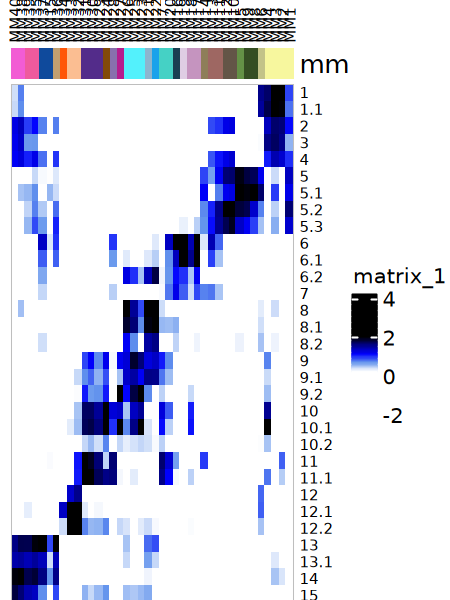

In [4]:
mm_1hot = crecls$mm_1hot_vclust
oc_1hot = setdiff(crecls$oc_1hot_vclust, crecls$oc_const_crecls)
mm_paper_id = numbering %>% filter(species == "mouse") %>% select(crecl, paper_id) %>% deframe()
oc_paper_id = numbering %>% filter(species == "rabbit") %>% select(crecl, paper_id) %>% deframe()

abs_shades = colorRampPalette(c("white", "white", "cornflowerblue", "blue", "darkblue", "black"))(1000)
mm_crecls = mm_crecl_sup_legc[rev(rownames(mm_crecl_sup_legc)),mm_1hot]
oc_crecls = oc_crecl_sup_legc[rev(rownames(oc_crecl_sup_legc)),oc_1hot]
colnames(mm_crecls) = mm_paper_id[colnames(mm_crecls)]
colnames(oc_crecls) = oc_paper_id[colnames(oc_crecls)]
state_heatmap = function(crecls, annotation, fontsize, ...) ComplexHeatmap::Heatmap(
    t(crecls) - colMeans(crecls),
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    show_row_names = TRUE,
    show_column_names = T,
    top_annotation = annotation,
    column_names_side = "top",
    col = circlize::colorRamp2(c(-2,seq(-0.2,2,l=998),3), abs_shades),
    height = unit(0.9, "npc"),
    row_title_gp = grid::gpar(fontfamily = "ArialMT", fontsize = fontsize),
    column_title_gp = grid::gpar(fontfamily = "ArialMT", fontsize = fontsize),
    row_names_gp = grid::gpar(fontfamily = "ArialMT", fontsize = fontsize),
    column_names_gp = grid::gpar(fontfamily = "ArialMT", fontsize = fontsize),
    use_raster = TRUE,
    row_title = NULL,
    border = TRUE,
    border_gp = grid::gpar(col = "grey", lwd = 0.5),
    ...
)
options(repr.plot.width=3, repr.plot.height=4)
draw(state_heatmap(mm_crecls, ComplexHeatmap::HeatmapAnnotation(show_legend = FALSE, mm = mm_mclst_type[rownames(mm_crecls)],
                                                                col = list(mm = mm_code_color)), 7))

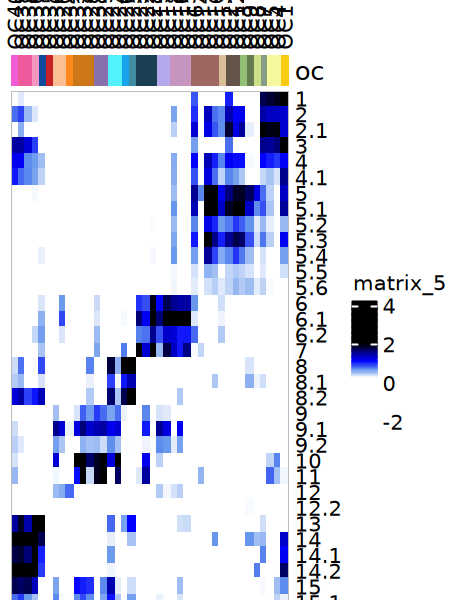

In [5]:
draw(state_heatmap(oc_crecls, ComplexHeatmap::HeatmapAnnotation(show_legend = FALSE, oc = oc_mclst_type[rownames(oc_crecls)],
                                                                col = list(oc = oc_code_color)), 10,
                   name = "matrix_5"))  # the name ComplexHeatmap gave it in the original session (the figure relabels the legend)

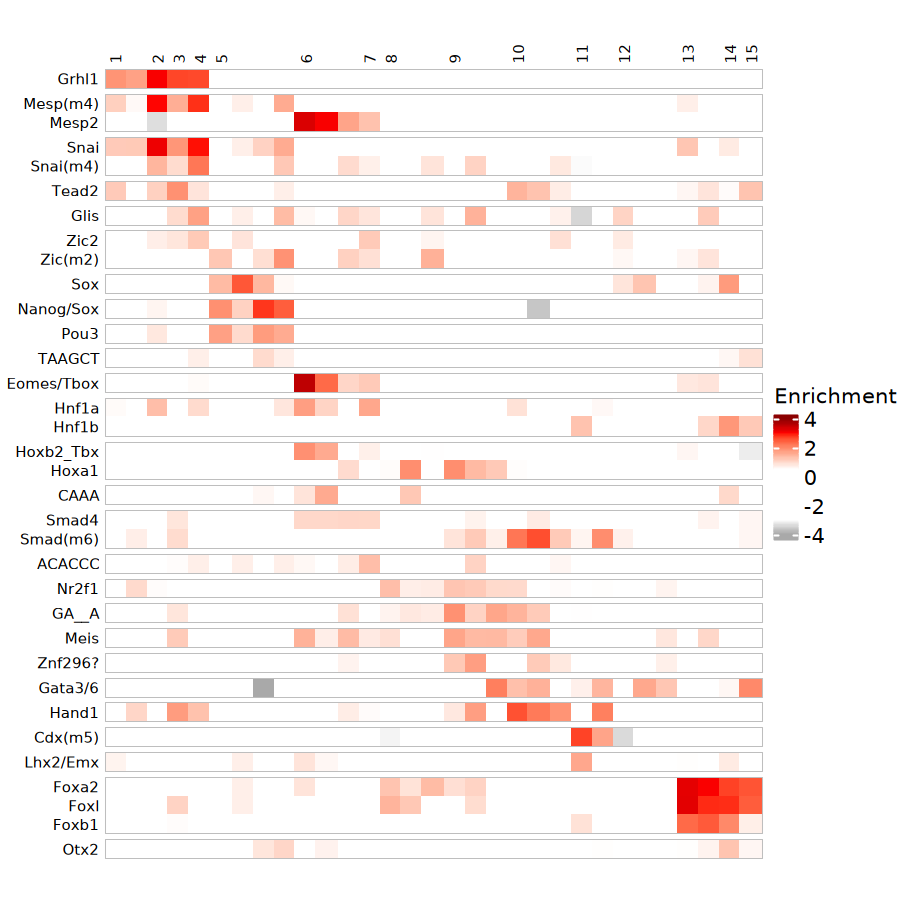

In [6]:
enrichment_heatmap = function(plot_mat, row_groups, ...) ComplexHeatmap::Heatmap(
    t(plot_mat),
    name = "Enrichment",
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    show_column_names = TRUE,
    column_names_side = "top",
    col = circlize::colorRamp2(c(-4, -3, 0, 0.5, 3, 4), c("darkgray", "white", "white", "white", "red", "darkred")),
    height = unit(0.9, "npc"),
    row_title_gp = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
    column_title_gp = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
    row_names_gp = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
    column_names_gp = grid::gpar(fontfamily = "ArialMT", fontsize = 7),
    use_raster = TRUE,
    row_split = row_groups,
    row_title = NULL,
    row_gap = unit(1, "mm"),
    border = TRUE,
    border_gp = grid::gpar(col = "gray", lwd = 0.5),
    ...
)
mm_enrich_mat = enrich_matrix(mm_enrich_df)[mm_1hot,]
mm_plot_mat = mm_enrich_mat[, order(apply(mm_enrich_mat, 2, which.max))]
mm_motif_ord_df = motif_order(mm_plot_mat)
mm_plot_mat = mm_plot_mat[, mm_motif_ord_df$motif]
rownames(mm_plot_mat) = ifelse(is.na(mm_renaming[rownames(mm_plot_mat)]),'', mm_renaming[rownames(mm_plot_mat)])
oc_plot_mat = enrich_matrix(oc_enrich_df)[oc_1hot, mm_motif_ord_df$motif]
rownames(oc_plot_mat) = ifelse(is.na(oc_renaming[rownames(oc_plot_mat)]),'', oc_renaming[rownames(oc_plot_mat)])
options(repr.plot.width=6, repr.plot.height=6)
draw(enrichment_heatmap(mm_plot_mat, mm_motif_ord_df$group, row_names_side = "left"))

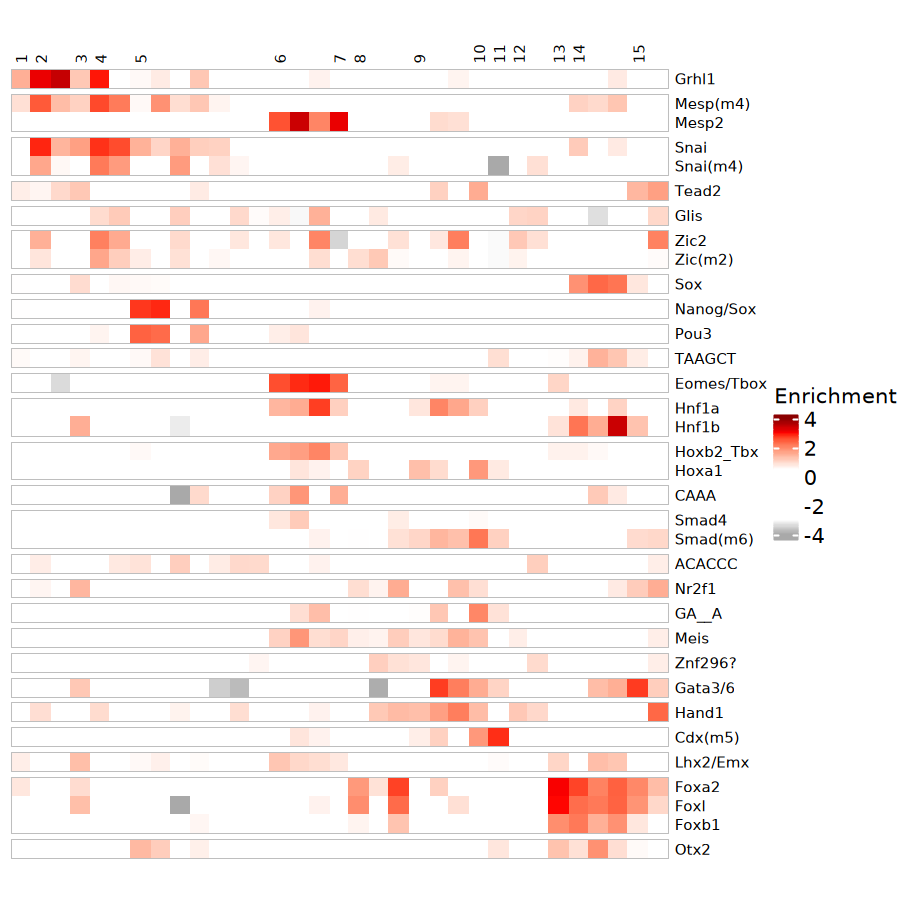

In [7]:
draw(enrichment_heatmap(oc_plot_mat, mm_motif_ord_df$group))

## 3. Figs 2B and 2C

Enrichment of the 33 anchor CRECls of each species (rows in anchor-pair order), correlated per motif between mouse and
rabbit.

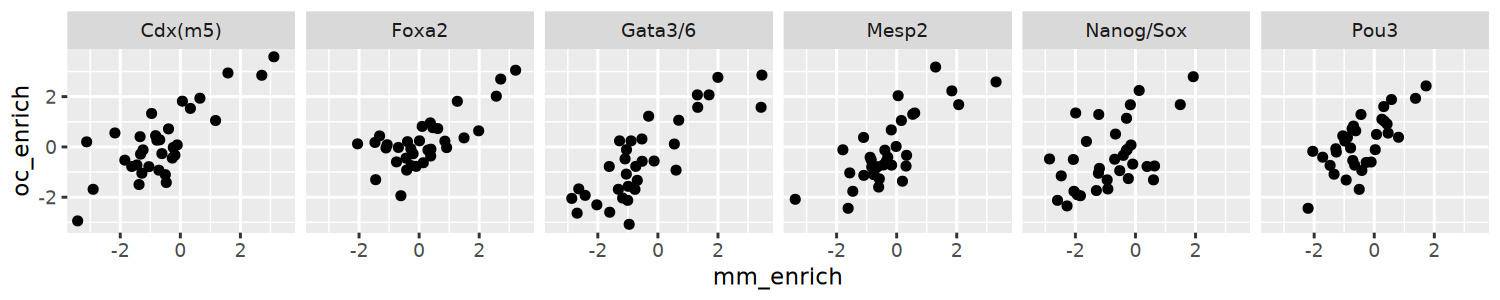

In [8]:
mm_enrich_mat = enrich_matrix(mm_enrich_df)[names(match_rabbit),]
mm_plot_mat = mm_enrich_mat[, order(apply(mm_enrich_mat, 2, which.max))]
mm_motif_ord_df = motif_order(mm_plot_mat)
mm_plot_mat = mm_plot_mat[, mm_motif_ord_df$motif]
oc_enrich_mat = enrich_matrix(oc_enrich_df)[match_rabbit,]
oc_plot_mat = oc_enrich_mat[, mm_motif_ord_df$motif]

full_motif_motif_cor_sup = tgs_cor(as.matrix(mm_plot_mat[names(match_rabbit),]), as.matrix(oc_plot_mat[match_rabbit,]))
motif_motif_cors = diag(full_motif_motif_cor_sup)
names(motif_motif_cors) = colnames(full_motif_motif_cor_sup)

options(repr.plot.width=10, repr.plot.height=2)
print(cbind(as.data.frame(mm_plot_mat[names(match_rabbit),]) %>% rownames_to_column("mm_crecl") %>% pivot_longer(!mm_crecl, names_to = "mm_motif", values_to = "mm_enrich"),
    as.data.frame(oc_plot_mat[match_rabbit,]) %>% rownames_to_column("oc_crecl") %>% pivot_longer(!oc_crecl, names_to = "oc_motif", values_to = "oc_enrich")) %>%
    filter(mm_motif %in% c("Mesp2", "Nanog/Sox", "Pou3", "Foxa2", "Cdx(m5)", "Gata3/6")) %>%
    ggplot(aes(x=mm_enrich, y=oc_enrich)) + geom_point() + facet_grid(~mm_motif))

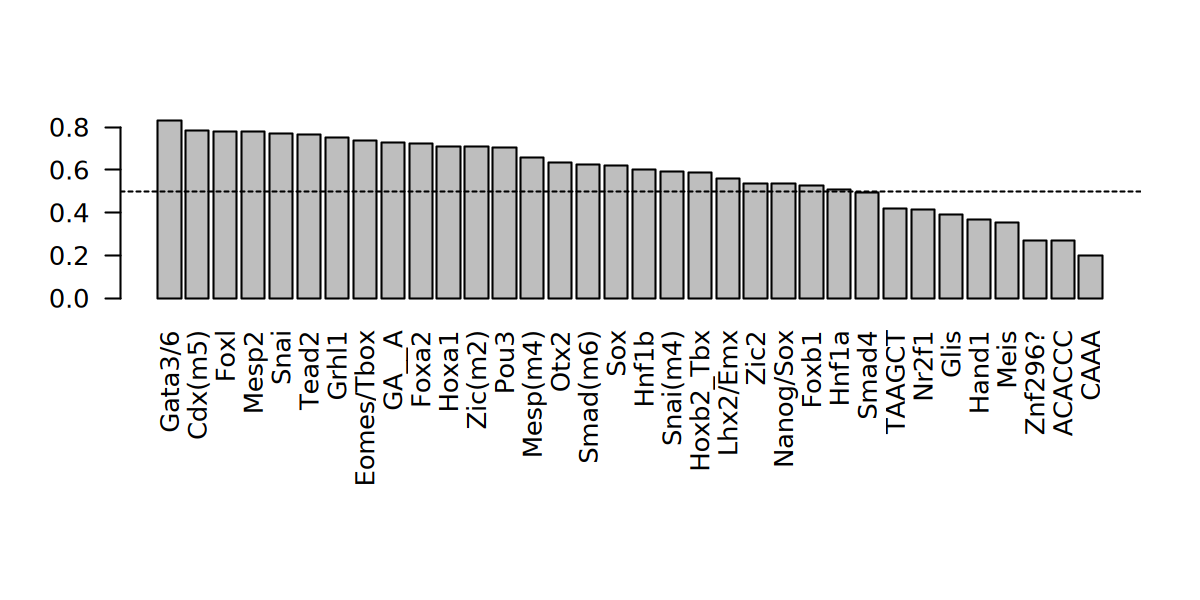

In [9]:
options(repr.plot.width=8, repr.plot.height=4)
par(mar = c(10, 4, 4, 2))
barplot(sort(motif_motif_cors, decreasing = T), las=2)
abline(h=0.5, lty=2)